# Computational complexity – Preprocessing

This notebook analyzes the computational complexity of the preprocessing functions in `cleaning.py`, line by line and globally, using O(n) notation (S7). It also compares the unoptimized and optimized versions of the replacement of missing values.

Notation used in this notebook:
- **n**: number of sprouts (rows), 2,796 in the raw data.
- **m**: number of columns, 35 in the raw data (29 of them are internodes).

In [1]:
# Make the project root importable, because this notebook is inside src/<module>/
import sys, os, inspect, timeit
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
# this lets the notebook find the src folder, which is two levels up
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import cleaning
raw = cleaning.load_data(os.path.join(ROOT, 'data', 'raw', 'cjs.csv'))
raw.shape

(2796, 35)

## `load_data`

In [2]:
# inspect.getsource shows the code of the function, so I can analyze it here
print(inspect.getsource(cleaning.load_data))

def load_data(path):
    """
    Load the raw Tree Growth dataset.

    Parameters
    ----------
    path : str
        Path or URL of the raw CSV file.

    Returns
    -------
    pandas.DataFrame
        Raw dataset, exactly as it is stored in the file.
    """
    return pd.read_csv(path)



*n = number of sprouts; m = number of columns (35).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def load_data(path):` | O(1) |
| 2 | `pd.read_csv(path)`: reads and parses the n × m cells of the file | O(n · m) |

**Global complexity:** **O(n · m)**, that is, **O(n)**, because the number of columns is fixed (m = 35).

## `replace_missing_loop`

In [3]:
print(inspect.getsource(cleaning.replace_missing_loop))

def replace_missing_loop(df):
    """
    Replace the '?' marks with NaN, cell by cell (unoptimized version).

    It goes through every column and every cell with apply + map, as in the
    Lab 2 notebook.

    Parameters
    ----------
    df : pandas.DataFrame
        Raw dataset.

    Returns
    -------
    pandas.DataFrame
        Dataset with NaN instead of '?'.
    """
    # Replace the '?' marks with NaN so pandas recognizes them as missing values
    return df.apply(lambda col: col.map(lambda x: np.nan if x == '?' else x))



*n = number of sprouts; m = number of columns (35).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def replace_missing_loop(df):` | O(1) |
| 2 | `df.apply(lambda col: ...)`: goes through the m columns | O(m) |
| 3 | `col.map(lambda x: ...)`: goes through the n cells of each column | O(n) per column |
| 4 | `np.nan if x == '?' else x`: one comparison | O(1) |

**Global complexity:** O(1) + O(m) × O(n) × O(1) = **O(n · m)**. Since the number of columns is fixed (m = 35) and only the number of sprouts grows, the complexity is **O(n)**.

## `replace_missing`

In [4]:
print(inspect.getsource(cleaning.replace_missing))

def replace_missing(df):
    """
    Replace the '?' marks with NaN in one vectorized step (optimized version).

    Parameters
    ----------
    df : pandas.DataFrame
        Raw dataset.

    Returns
    -------
    pandas.DataFrame
        Dataset with NaN instead of '?'.
    """
    # I used replace here to get the vectorized version of apply + map, I took this idea from the notebook S7
    return df.replace('?', np.nan)



*n = number of sprouts; m = number of columns (35).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def replace_missing(df):` | O(1) |
| 2 | `df.replace('?', np.nan)`: checks the n × m cells in vectorized code | O(n · m) |

**Global complexity:** **O(n · m)**, that is, **O(n)** with a fixed number of columns (m = 35). It has the same order as `replace_missing_loop`, but it is faster because pandas checks the cells internally instead of running a Python `lambda` for each one: the constant is smaller, not the order.

## `convert_internodes`

In [5]:
print(inspect.getsource(cleaning.convert_internodes))

def convert_internodes(df):
    """
    Convert the internode columns from text to float.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset where the '?' marks were already replaced with NaN.

    Returns
    -------
    pandas.DataFrame
        Dataset with the 29 internode columns as float.
    """
    df = df.copy()
    # Convert the internode columns from text to numbers
    df[INTERNODE_COLS] = df[INTERNODE_COLS].astype(float)
    return df



*n = number of sprouts; m = number of columns (35); L = number of internode columns (29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def convert_internodes(df):` | O(1) |
| 2 | `df = df.copy()`: copies the n × m cells | O(n · m) |
| 3 | `df[INTERNODE_COLS].astype(float)`: converts the n × 29 internode cells | O(n · L) |
| 4 | `return df` | O(1) |

**Global complexity:** O(n · m) + O(n · L) = **O(n)**, because the number of columns (m = 35) and of internode columns (L = 29) are fixed; only the number of sprouts grows.

## `encode_categories`

In [6]:
print(inspect.getsource(cleaning.encode_categories))

def encode_categories(df):
    """
    Convert the label columns to category and encode the treatment.

    TR, TREE and BR are labels, not measurements, so they are converted to the
    category type. TR is the class variable, so it is also encoded as integers
    from 0 to 5 (alphabetical order) in the new column TR_code.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the internode columns already converted.

    Returns
    -------
    pandas.DataFrame
        Dataset with categorical columns and the new column TR_code.
    """
    df = df.copy()
    # Convert the label columns, that are treatment, tree and branch, to the category type
    df[CATEGORICAL_COLS] = df[CATEGORICAL_COLS].astype('category')
    # Encode the treatment, class variable, as integers from 0 to 5
    label_encoder = LabelEncoder()
    df['TR_code'] = label_encoder.fit_transform(df['TR'])
    return df



*n = number of sprouts; m = number of columns (35).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def encode_categories(df):` | O(1) |
| 2 | `df = df.copy()`: copies the n × m cells | O(n · m) |
| 3 | `astype('category')` on 3 columns: each value is looked up in a table of categories (hashing) | O(n) |
| 4 | `label_encoder = LabelEncoder()` | O(1) |
| 5 | `label_encoder.fit_transform(df['TR'])`: finds the unique treatments by sorting the n values | O(n log n) |
| 6 | `return df` | O(1) |

**Global complexity:** O(n · m) + O(n) + O(n log n) = **O(n log n)**. The dominant line is `fit_transform`, because finding the unique classes requires sorting the column.

## `find_inconsistent`

In [7]:
print(inspect.getsource(cleaning.find_inconsistent))

def find_inconsistent(df):
    """
    Find the sprouts where IN does not match the number of internodes with data.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the internode columns as float.

    Returns
    -------
    pandas.DataFrame
        Rows where IN is different from the number of non-missing internodes.
    """
    # Check if the data makes sense: IN says how many internodes each sprout has,
    # so I count the internodes that have a value and compare both numbers
    in_count = df[INTERNODE_COLS].notna().sum(axis=1)
    return df[df['IN'] != in_count]



*n = number of sprouts; m = number of columns (35); L = number of internode columns (29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def find_inconsistent(df):` | O(1) |
| 2 | `df[INTERNODE_COLS].notna()`: checks the n × 29 internode cells | O(n · L) |
| 3 | `.sum(axis=1)`: adds the 29 values of each row | O(n · L) |
| 4 | `df['IN'] != in_count`: one comparison per sprout | O(n) |
| 5 | `df[...]`: keeps the rows where the comparison is True | O(n · m) |

**Global complexity:** **O(n · L)**, that is, **O(n)**, because L = 29 and m = 35 are fixed.

## `remove_inconsistent`

In [8]:
print(inspect.getsource(cleaning.remove_inconsistent))

def remove_inconsistent(df):
    """
    Remove the sprouts where IN does not match the internode data.

    In this dataset only one sprout (N = 1067) is inconsistent. TL cannot tell
    which value is correct, so the sprout is removed.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the internode columns as float.

    Returns
    -------
    pandas.DataFrame
        Dataset without the inconsistent sprouts.
    """
    # Only one sprout, N = 1067, has a problem: IN says 3, but it has 4 internodes.
    # TL can't tell me which one is right, so I remove this sprout, it's only 1 of 2796
    bad = find_inconsistent(df)
    return df.drop(index=bad.index)



*n = number of sprouts; m = number of columns (35).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `def remove_inconsistent(df):` | O(1) |
| 2 | `bad = find_inconsistent(df)`: see the previous function | O(n) |
| 3 | `df.drop(index=bad.index)`: builds a new table without those rows | O(n · m) |

**Global complexity:** O(n) + O(n · m) = **O(n)**, with a fixed number of columns.

## `preprocess`

In [9]:
print(inspect.getsource(cleaning.preprocess))

def preprocess(path, optimized=True):
    """
    Run the whole preprocessing pipeline.

    Parameters
    ----------
    path : str
        Path or URL of the raw CSV file.
    optimized : bool, optional
        If True, use the vectorized replacement of '?'. Default True.

    Returns
    -------
    pandas.DataFrame
        Clean dataset, ready for feature extraction.
    """
    df = load_data(path)
    df = replace_missing(df) if optimized else replace_missing_loop(df)
    df = convert_internodes(df)
    df = encode_categories(df)
    df = remove_inconsistent(df)
    return df



*n = number of sprouts.*

| Line | Code | Complexity |
|---|---|---|
| 1 | `df = load_data(path)` | O(n) |
| 2 | `replace_missing(df)` or `replace_missing_loop(df)` | O(n) |
| 3 | `df = convert_internodes(df)` | O(n) |
| 4 | `df = encode_categories(df)` | O(n log n) |
| 5 | `df = remove_inconsistent(df)` | O(n) |
| 6 | `return df` | O(1) |

**Global complexity:** the steps run one after the other, so their complexities are added: O(n) + O(n) + O(n) + O(n log n) + O(n) = **O(n log n)**. The dominant step is the encoding of the treatment, which sorts the classes.

## Optimization: replacement of missing values

`replace_missing_loop` visits every cell with a Python function (`apply` + `map` + `lambda`), while `replace_missing` uses `DataFrame.replace`, which does the same work in vectorized code. Both give the same result:

In [10]:
cleaning.replace_missing_loop(raw).equals(cleaning.replace_missing(raw))

True

In [11]:
def time_vs_n(func, make_input, sizes, repeat=3):
    """Return the best execution time of func for each input size (as in S7, with timeit)."""
    times = []
    for n in sizes:
        data = make_input(n)
        times.append(min(timeit.repeat(lambda: func(data), number=1, repeat=repeat)))
    return times

sizes = [1000, 2000, 4000, 8000, 16000]
make_input = lambda n: raw.sample(n, replace=True, random_state=0).reset_index(drop=True)

t_loop = time_vs_n(cleaning.replace_missing_loop, make_input, sizes)
t_opt = time_vs_n(cleaning.replace_missing, make_input, sizes)

pd.DataFrame({'n': sizes, 'loop (s)': t_loop, 'optimized (s)': t_opt,
              'speed-up': np.array(t_loop) / np.array(t_opt)}).round(4)

,n,loop (s),optimized (s),speed-up
0,1000,0.0087,0.0028,3.1348
1,2000,0.0137,0.0045,3.0489
2,4000,0.0260,0.0070,3.7213
3,8000,0.0441,0.0128,3.4508
4,16000,0.0869,0.0238,3.6550


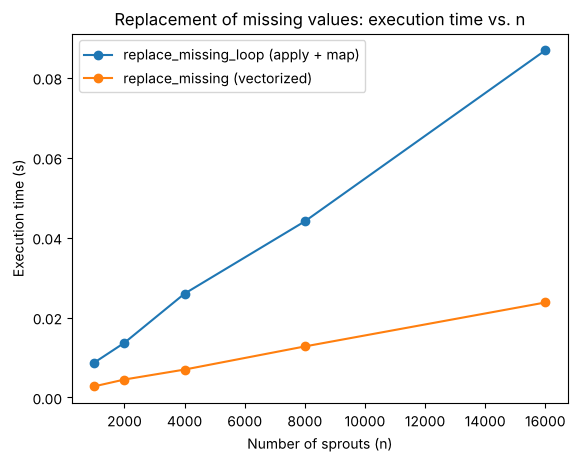

In [12]:
plt.plot(sizes, t_loop, 'o-', label='replace_missing_loop (apply + map)')
plt.plot(sizes, t_opt, 'o-', label='replace_missing (vectorized)')
plt.xlabel('Number of sprouts (n)')
plt.ylabel('Execution time (s)')
plt.title('Replacement of missing values: execution time vs. n')
plt.legend()
plt.show()

**Comparison.** Both versions check the n × m cells of the table, so both are **O(n · m)**, that is, **O(n)** with a fixed number of columns. The order is the same, but the optimized version was about **4 times faster** in all the tested sizes: `replace_missing_loop` runs a Python `lambda` for every cell, while `DataFrame.replace` does the same work in compiled, vectorized code. The optimization reduces the constant (the cost per cell), not the order, and both versions give exactly the same result.